In [15]:
%matplotlib widget
from matplotlib import pyplot as plt

from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.signal import peak_widths
import numpy as np
import os
import importlib
from sklearn.metrics import mean_squared_error
import copy

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import P_and_P_func
importlib.reload(P_and_P_func)
from P_and_P_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import PaP_plotting_func
importlib.reload(PaP_plotting_func)
from PaP_plotting_func import *



fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

### Get the data with a treated thermal part

In [16]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Silice thick\AR 4,5\zone 2\D1'
dir_name = r'16-Oct-2026_PaP_Pp10uW_ldap410nm_ldas680nm'



dir_name += '_treated'
filename='Trace'

filename_thermic = filename + '_thermal_fitted'

Trace_thermic = get_PaP_dataset(dir_root + '\\' + dir_name, filename_thermic)

### Get the data that we'll use for acoustic fitting

In [17]:
Trace_acoustic = copy.deepcopy(Trace_thermic)
dir_save_treated_data = dir_root + '\\' + dir_name

Create an independant copy to make acoustic treatment

In [18]:
n_exp = 3
Trace_acoustic.remove_thermic_part(Trace_thermic, n_exp)

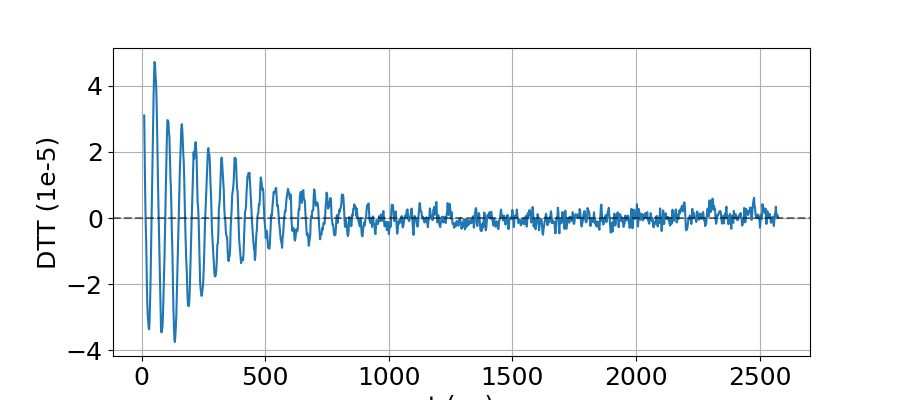

In [19]:
fig_acoustic_raw , ax_acoustic_raw = plt.subplots(figsize = (9,4))

ax_acoustic_raw = Plot_acoustic_raw(Trace_acoustic, ax_acoustic_raw)

plt.show()


save_in_dir(fig_acoustic_raw, dir_save_treated_data, 'Acoustic signal raw')

Make TF

In [20]:
height = 0.5e-7
threshold = 1e-7
ylim = 1500e-7

Trace_acoustic.tf_acoustic = Trace_acoustic.study_tf(Trace_acoustic.DTT_acoustic, Trace_acoustic.delay, Trace_acoustic.dt, height=height, threshold = threshold )

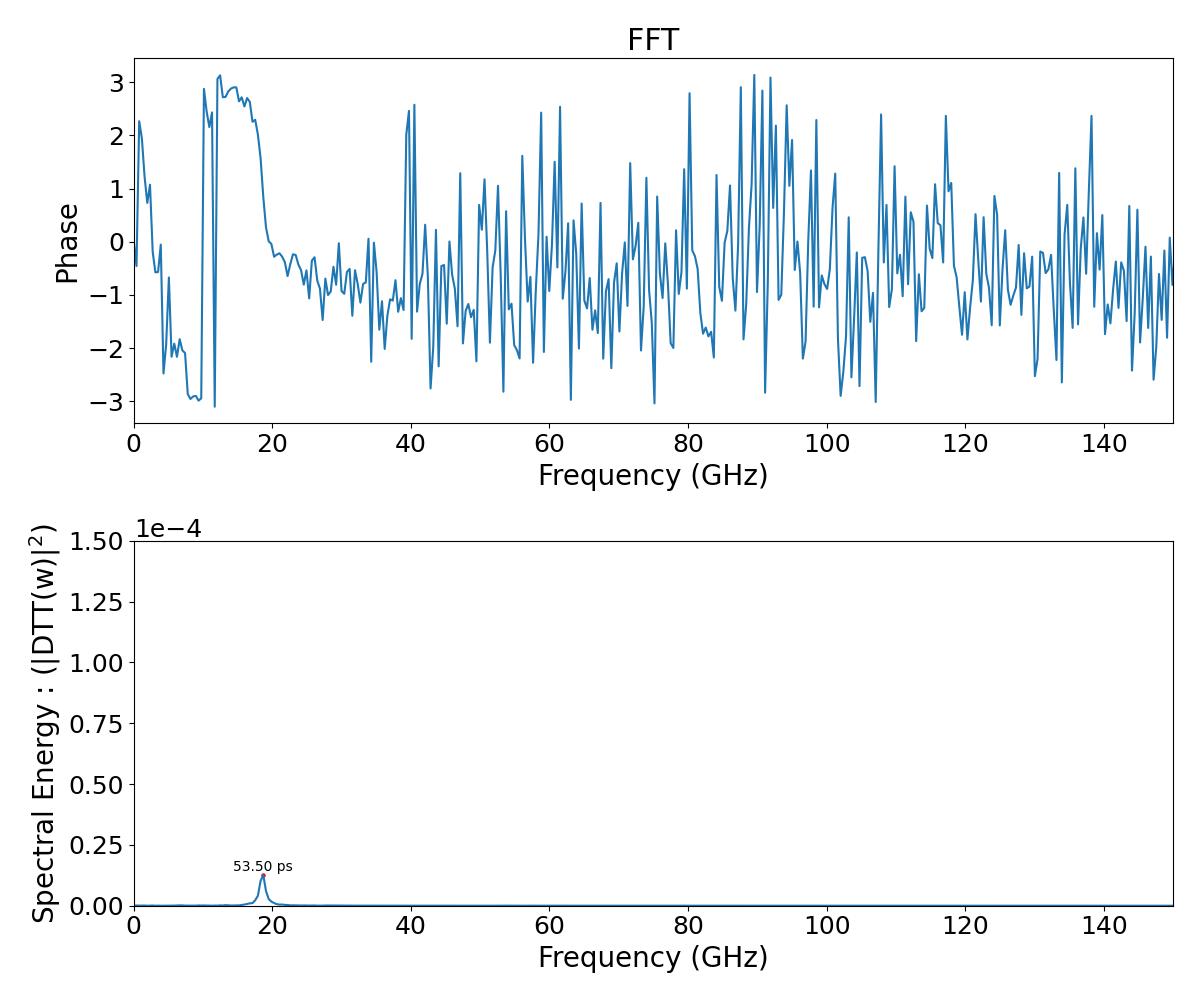

In [21]:
fig_raw_tf, ax_raw_tf = plt.subplots(nrows=2, figsize = (12, 10))

normalize_magnitude = False

plot_tf_phase(Trace_acoustic.tf_acoustic, ax_raw_tf[0], ylim=ylim, xlim=(0, 150))
plot_tf_module(Trace_acoustic.tf_acoustic, ax_raw_tf[1], ylim=ylim, xlim=(0, 150), normalized=normalize_magnitude)

if normalize_magnitude :
    ax_raw_tf[1].set_ylim((0, 1))
plt.tight_layout()
plt.show()

save_in_dir(fig_raw_tf, dir_save_treated_data, 'TF acoustic')

## Acoustic time interpolation

Make bounds and initial guess

In [22]:
#p0 = A1, tau1, T1, phi1, A2, tau2, T2, phi2, A3, tau3, T3, phi3, A4, tau4, T4, phi4
A1_0, tau1_0, T1_0, phi1_0 = 4.3e-5, 330, 53.8, (80)*np.pi/180
A2_0, tau2_0, T2_0, phi2_0 = 0.8e-5, 300, 70, (80)*np.pi/180
A3_0, tau3_0, T3_0, phi3_0 = 3e-5, 100, 200, 80*np.pi/180
A4_0, tau4_0, T4_0, phi4_0 = 0.5e-5, 200, 30, 0


p0 = A1_0, tau1_0, T1_0, phi1_0, A2_0, tau2_0, T2_0, phi2_0, A3_0, tau3_0, T3_0, phi3_0, A4_0, tau4_0, T4_0, phi4_0

Bounds_low = [ 0, 0, 0, -np.pi, 0, 0, 0, -np.pi, 0, 0, 0, -np.pi, 0, 0, 0, -np.pi]
Bounds_high= [np.inf,np.inf,np.inf,np.pi,np.inf, np.inf, np.inf, np.pi,np.inf,np.inf,np.inf,np.pi,np.inf, np.inf, np.inf, np.pi]

In [23]:
Trace_acoustic.fit_acoustic(p0,Bounds_high, Bounds_low)

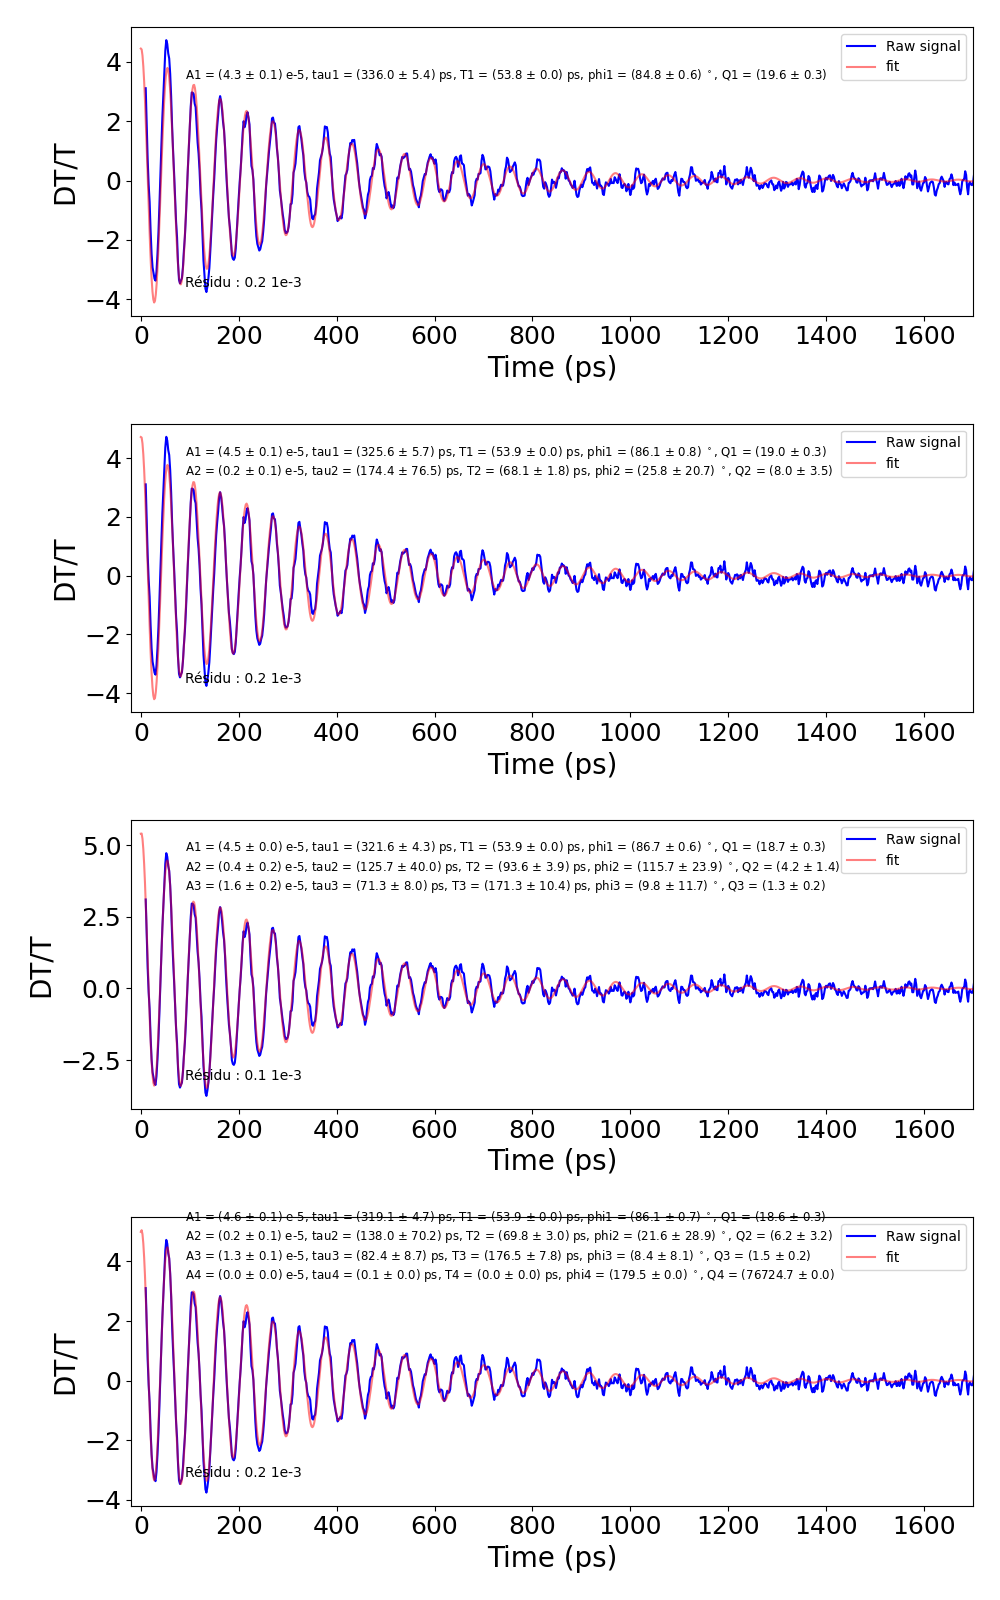

In [24]:
tmax=1700

fig_fit_acoustic, ax_fit_acoustic = plt.subplots(nrows = 4, figsize=(10,16))

Plot_acoustic_fit(Trace_acoustic, ax_fit_acoustic[0], n_modes=1, tmax=tmax )
Plot_acoustic_fit(Trace_acoustic, ax_fit_acoustic[1], n_modes=2, tmax=tmax )
Plot_acoustic_fit(Trace_acoustic, ax_fit_acoustic[2], n_modes=3, tmax=tmax )
Plot_acoustic_fit(Trace_acoustic, ax_fit_acoustic[3], n_modes=4, tmax=tmax )
plt.tight_layout()
plt.show()

save_in_dir(fig_fit_acoustic, dir_save_treated_data, 'Fit acoustic - all modes')

## Acoustic study synthesis

In [25]:
n_modes_acoustic = 3
n_exp_thermic = n_exp

Trace_acoustic.n_modes_acoustic = n_modes_acoustic
Trace_acoustic.n_exp_thermic = n_exp_thermic
tmax = tmax

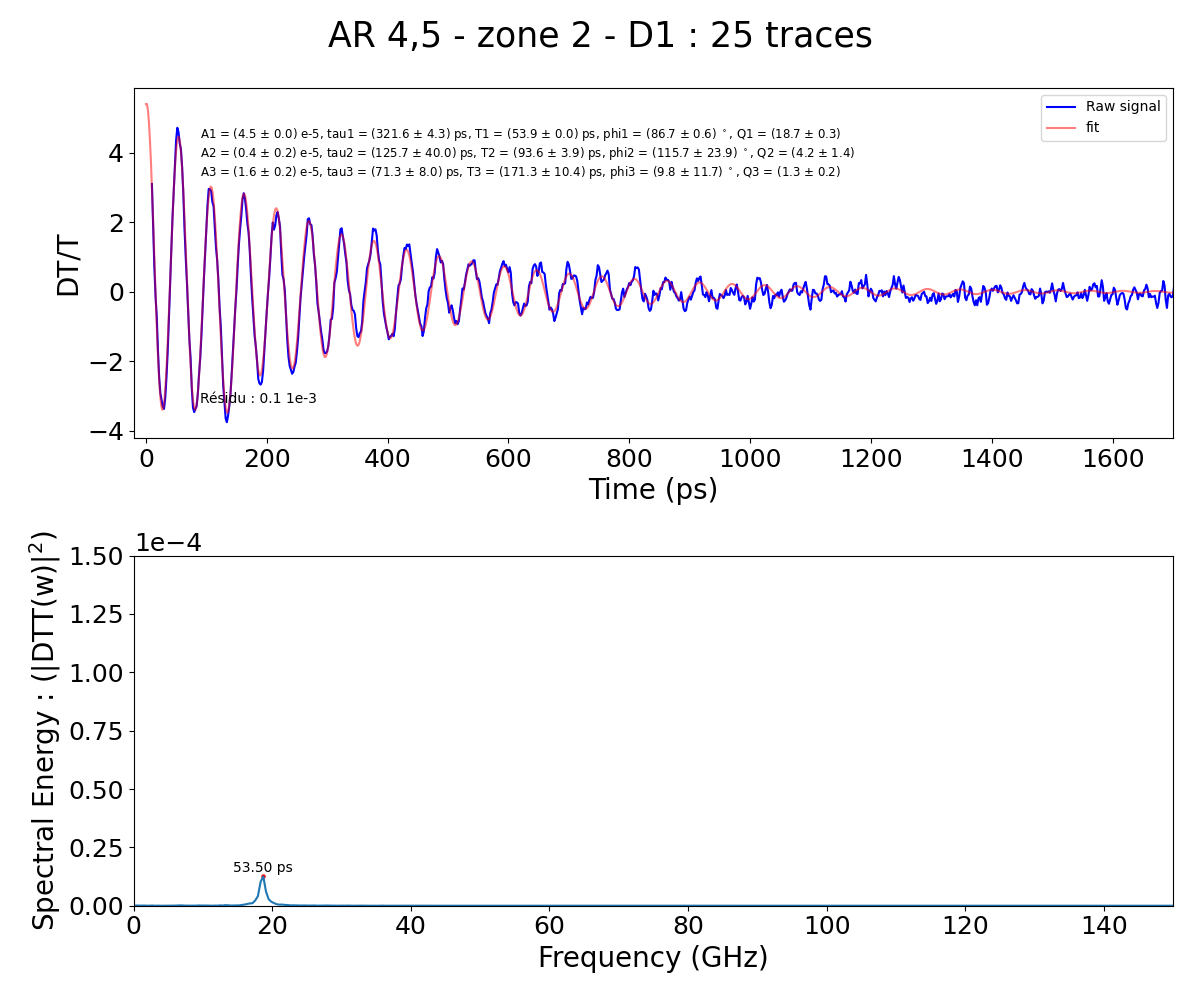

In [26]:
fig_synthese, ax = figs, ax = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 10),
)

#Plot_acoustic_raw(Trace_acoustic, ax[0])
Plot_acoustic_fit(Trace_acoustic, ax[0], n_modes=n_modes_acoustic, tmax=tmax )
plot_tf_module(Trace_acoustic.tf_acoustic, ax[1], ylim=ylim, xlim=(0, 150))

list_info = Trace_acoustic.dir_root.split('\\')
plt.suptitle('{} - {} - {} : {} traces'.format(list_info[-3], list_info[-2], list_info[-1], Trace_acoustic.n_traces), fontsize=25)
plt.tight_layout()


save_in_dir(fig_synthese, dir_save_treated_data, 'Synthèse fit acoustic')

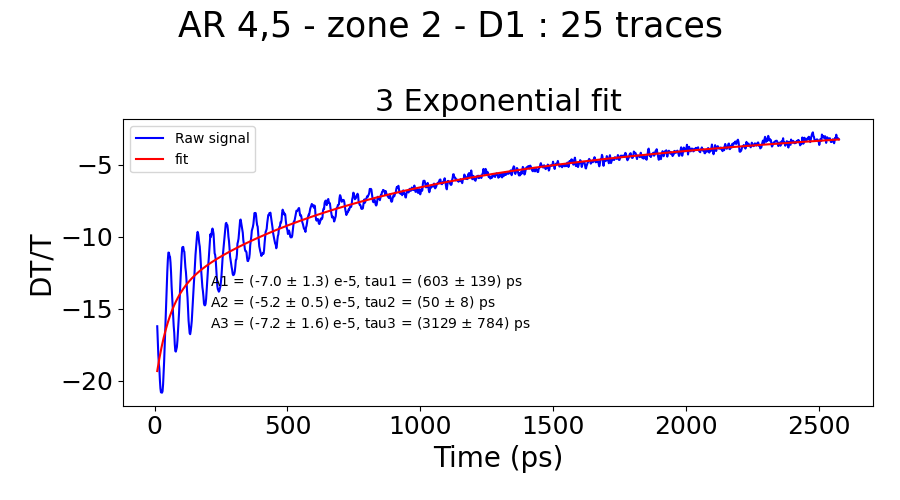

In [27]:
fig_synthese_thermal, ax_synth_thermal = plt.subplots(figsize=(9,5))

Plot_thermal_fit(Trace_acoustic, ax_synth_thermal, n_exp=n_exp_thermic )
list_info = Trace_acoustic.dir_root.split('\\')
plt.suptitle('{} - {} - {} : {} traces'.format(list_info[-3], list_info[-2], list_info[-1], Trace_acoustic.n_traces), fontsize=25)

plt.tight_layout()

save_in_dir(fig_synthese_thermal, dir_save_treated_data, 'Synthèse fit thermal')

In [28]:
dir_to_save = Trace_acoustic.dir_root + '\\' + Trace_acoustic.dir_name + r'_treated'
filename_acoustic = filename + '_acoustic_fitted'

save_PaP_dataset(Trace_acoustic, dir_to_save, filename_acoustic)

save_signal_and_fits_curves(Trace_acoustic)
save_fits_coeffs_thermic(Trace_acoustic)
save_fits_coeffs_acoustic(Trace_acoustic)

## Fit by hand